# 3. Modelagem: aluguéis por hora com target em log

Objetivos principais:
- treinar **somente com 2011**; 2012 fica inteiro como "produção" para o whylogs;
- usar `log1p(cnt)` como target e **testar** a correção de viés log-normal na volta;
- comparar com um baseline simples (média por hora × tipo de dia);
- salvar a pipeline e as métricas.

As definições de features, pipeline e do wrapper `CountModel` ficam em `src/bike.py`, para o notebook do whylogs usar exatamente o mesmo código.

In [1]:
import sys
from pathlib import Path
import json
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, r2_score

sys.path.append("..")
from src.bike import FEATURES, NUM_FEATURES, CAT_FEATURES, LABEL, LEAKY_COLUMNS, BACKEND, build_pipeline, CountModel, rmse

BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#52514e"
print("backend do modelo:", BACKEND)
print("features:", FEATURES)
print("fora do modelo:", LEAKY_COLUMNS)

backend do modelo: lightgbm
features: ['hour', 'month', 'holiday', 'workingday', 'temp', 'atemp', 'humidity', 'windspeed', 'season', 'weekday', 'weather']
fora do modelo: ['casual', 'registered', 'year', 'date', 'datetime']


In [2]:
df = pd.read_parquet("../data/processed/bike_clean.parquet")
df2011 = df[df["year"] == 2011].copy()
print("2011:", df2011.shape, "| 2012 (não usado aqui):", (df["year"] == 2012).sum())

2011: (8645, 17) | 2012 (não usado aqui): 8734


## 1 — Validação temporal dentro de 2011

Um *split* aleatório entre horas vizinhas vaza informação (a hora 8h e a hora 9h do mesmo dia são quase iguais). Um *split* "jan–out treino / nov–dez validação" deixa a validação só no inverno.

Usamos um **split em blocos**: os dias **24 em diante de cada mês** vão para a validação. Assim todas as estações aparecem no treino e na validação, e nenhum dia é dividido entre os dois.

In [3]:
is_valid = df2011["date"].dt.day >= 24
train, valid = df2011[~is_valid], df2011[is_valid]
print(f"treino: {len(train)} horas | validação: {len(valid)} horas ({is_valid.mean():.0%})")

X_train, y_train = train[FEATURES], train[LABEL].astype(float)
X_valid, y_valid = valid[FEATURES], valid[LABEL].astype(float)

treino: 6562 horas | validação: 2083 horas (24%)


## 2 — Baseline

Média de `cnt` por **hora × dia útil** no treino. Captura o padrão casa–trabalho e serve de piso: o modelo só vale a pena se for bem melhor que isso.

In [4]:
base_table = train.groupby(["hour", "workingday"])[LABEL].mean()
pred_base = valid.set_index(["hour", "workingday"]).index.map(base_table).to_numpy()

def metricas(y, p):
    return {
        "RMSE": rmse(y, p),
        "MAE": mean_absolute_error(y, p),
        "R2": r2_score(y, p),
        "RMSLE": rmse(np.log1p(y), np.log1p(np.clip(p, 0, None))),
    }

resultados = {"baseline (hora × dia útil)": metricas(y_valid, pred_base)}
pd.DataFrame(resultados).T.round(3)

,RMSE,MAE,R2,RMSLE
baseline (hora × dia útil),83.272,59.009,0.626,0.667


## 3 — Pipeline e treino em log

- numéricas: imputação pela mediana (`humidity` tem os NaN da falha de sensor);
- categóricas (`season`, `weekday`, `weather`): imputação pela moda + `OneHotEncoder(handle_unknown='ignore')`;
- regressor: LightGBM (ou RandomForest como *fallback*).

In [5]:
pipe = build_pipeline()
pipe.fit(X_train, np.log1p(y_train))
pred_log = pipe.predict(X_valid)
print("RMSE no espaço log:", round(rmse(np.log1p(y_valid), pred_log), 4))

RMSE no espaço log: 0.4149


## 4 — Correção de viés log-normal: vale a pena aqui?

Treinar em log e voltar com `expm1` estima a **mediana**, não a média. A correção clássica (usada no projeto do Ames) é:

$$\text{Pred}_{\text{corrigido}} = \exp\left(\text{pred}_{\text{log}} + 0,5 \cdot \sigma_{\text{resid}}^2\right) - 1$$

Ela supõe que os resíduos em log têm **a mesma variância em todas as faixas**. Estimamos $\sigma$ na **validação** (no treino ele sairia pequeno demais) e deixamos os números decidirem.

In [6]:
resid_log = np.log1p(y_valid) - pred_log
sigma_resid = float(np.std(resid_log, ddof=0))
print("sigma_resid (validação, log):", round(sigma_resid, 4))

pred_nocorr = np.expm1(pred_log)
pred_corr = CountModel(pipe, sigma_resid).predict(X_valid)

resultados["modelo (expm1, sem correção)"] = metricas(y_valid, pred_nocorr)
resultados["modelo (com correção de viés)"] = metricas(y_valid, pred_corr)
display(pd.DataFrame(resultados).T.round(3))

vies = {
    "sem correção": pred_nocorr.sum() / y_valid.sum() - 1,
    "com correção": pred_corr.sum() / y_valid.sum() - 1,
}
print("soma real na validação:", int(y_valid.sum()))
for k, v in vies.items():
    print(f"viés da soma prevista ({k}): {v:+.1%}")

sigma_resid (validação, log): 0.4141


,RMSE,MAE,R2,RMSLE
baseline (hora × dia útil),83.272,59.009,0.626,0.667
"modelo (expm1, sem correção)",41.126,26.210,0.909,0.415
modelo (com correção de viés),43.974,28.074,0.896,0.429


soma real na validação: 299358
viés da soma prevista (sem correção): -0.9%
viés da soma prevista (com correção): +8.0%


A correção **piorou** o RMSE e passou a superestimar o total. Dois motivos:

1. Ela multiplica **toda** previsão pelo mesmo fator $e^{0,5\sigma^2}$. Como o modelo sem correção já acerta a soma quase em cheio, esse fator empurra tudo para cima;
2. A hipótese de resíduos com variância constante não vale aqui, como mostra o desvio dos resíduos em log por faixa de horário:

In [7]:
print("fator multiplicativo da correção:", round(float(np.exp(0.5 * sigma_resid ** 2)), 3))

faixa = pd.cut(valid["hour"], [-1, 5, 9, 15, 19, 23], labels=["0–5h", "6–9h", "10–15h", "16–19h", "20–23h"])
het = pd.DataFrame({"resid_log": resid_log.to_numpy(), "faixa": faixa.values, "cnt": y_valid.to_numpy()})
het.groupby("faixa", observed=True).agg(
    desvio_resid_log=("resid_log", "std"), media_cnt=("cnt", "mean"), horas=("cnt", "size")
).round(3)

fator multiplicativo da correção: 1.09


,desvio_resid_log,media_cnt,horas
faixa,,,
0–5h,0.489,20.125,505
6–9h,0.486,157.917,350
10–15h,0.338,172.479,528
16–19h,0.378,286.949,352
20–23h,0.347,120.256,348


Na madrugada e no início da manhã (quando o uso sobe de quase zero para o pico em poucas horas) o desvio em log é bem maior do que no resto do dia. Um $\sigma$ único, puxado por essas faixas, infla as previsões também nas horas de maior volume.

**Decisão:** usar a correção só se ela reduzir o viés da soma **e** não piorar o RMSE. Aqui ela não passa, então o modelo final usa `expm1` puro (`sigma = 0`). O valor de $\sigma$ fica registrado no `metrics.json` para referência.

In [8]:
rmse_nc = resultados["modelo (expm1, sem correção)"]["RMSE"]
rmse_c = resultados["modelo (com correção de viés)"]["RMSE"]
USE_BIAS_CORRECTION = abs(vies["com correção"]) < abs(vies["sem correção"]) and rmse_c <= rmse_nc
SIGMA_USED = sigma_resid if USE_BIAS_CORRECTION else 0.0
print("usar correção de viés?", USE_BIAS_CORRECTION, "| sigma usado no modelo final:", round(SIGMA_USED, 4))

usar correção de viés? False | sigma usado no modelo final: 0.0


## 5 — Uma semana de validação

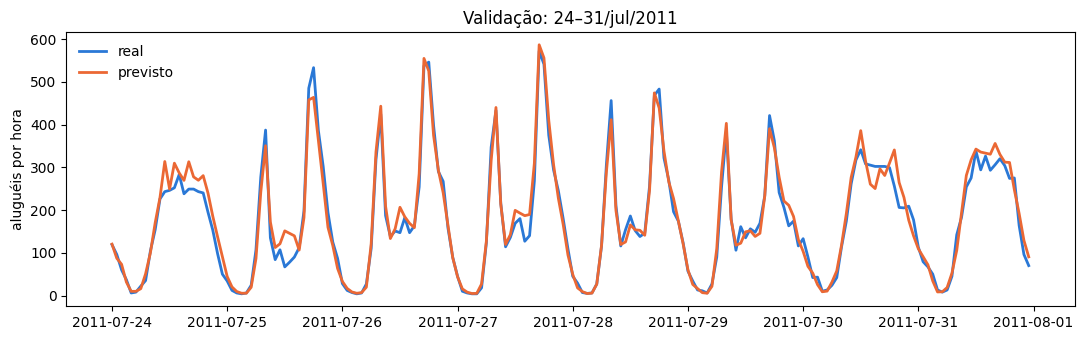

In [9]:
semana = valid[(valid["date"] >= "2011-07-24") & (valid["date"] < "2011-08-01")]
p_sem = CountModel(pipe, SIGMA_USED).predict(semana)

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(semana["datetime"], semana[LABEL], color=BLUE, lw=2, label="real")
ax.plot(semana["datetime"], p_sem, color=ORANGE, lw=2, label="previsto")
ax.set_ylabel("aluguéis por hora"); ax.set_title("Validação: 24–31/jul/2011")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()

## 6 — Modelo final e janela de referência

**Não** re-treinamos em 2011 inteiro. O modelo que vai para "produção" é o treinado nos dias 1–23 de cada mês, e o holdout (dias 24+ de 2011, que o modelo **nunca viu**) vira a **janela de referência** do monitoramento.

Por quê: o monitoramento compara o desempenho na referência com o desempenho em produção. Se a referência fosse o próprio treino, o erro de referência sairia artificialmente baixo (o LightGBM decora boa parte do treino) e qualquer lote novo pareceria "degradado". Com o holdout, a comparação é justa: o que mudar de 2011 para 2012 é drift, não *overfitting*.

In [10]:
in_sample = rmse(y_train, CountModel(pipe, SIGMA_USED).predict(X_train))
out_sample = resultados["modelo (expm1, sem correção)"]["RMSE"] if not USE_BIAS_CORRECTION else resultados["modelo (com correção de viés)"]["RMSE"]
print(f"RMSE no próprio treino: {in_sample:.1f} | RMSE no holdout: {out_sample:.1f}")

RMSE no próprio treino: 19.0 | RMSE no holdout: 41.1


In [11]:
OUT = Path("..") / "models"
OUT.mkdir(parents=True, exist_ok=True)
joblib.dump(pipe, OUT / "pipeline_2011.joblib")

metrics = {
    "backend": BACKEND,
    "train_window": "2011, dias 1 a 23 de cada mês",
    "reference_window": "2011, dias 24 em diante de cada mês (holdout)",
    "sigma_resid_log": sigma_resid,
    "use_bias_correction": bool(USE_BIAS_CORRECTION),
    "sigma_used": float(SIGMA_USED),
    "validation": {k: {m: float(v) for m, v in r.items()} for k, r in resultados.items()},
    "features": FEATURES,
    "cat_features": CAT_FEATURES,
}
(OUT / "metrics.json").write_text(json.dumps(metrics, indent=2, ensure_ascii=False))
print("pipeline salvo em", OUT / "pipeline_2011.joblib")
print("métricas salvas em", OUT / "metrics.json")

pipeline salvo em ../models/pipeline_2011.joblib
métricas salvas em ../models/metrics.json
